## INF201 - Deliverable 1

### Group info:

ID: `G5_4`

Members:
* Stig Espen Paulsberg
* Vinicius Millan Santa Catharina
* Zaur Kambiev 

### Imports

In [126]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
import requests
import yaml
from tabulate import tabulate


### Client ID

Read the client ID from `config.yaml`

In [127]:
with open("config.yaml") as file:
    config = yaml.safe_load(file)

client_id = config["met_api"]["client_id"]

In [128]:
# Add client id as parameter

def data_request_df(sources: str, elements: str, referencetime: str) -> pd.DataFrame:
    '''Requests data from Frost API and return as a pandas DataFrame.

    Parameters
    ----------
    sources : str
        The ID of the weather station (e.g., "SN17850").
    elements : str
        The elements for the data request (e.g., "mean(air_temperature P1D)").
    referencetime : str
        Date range.
        Format: YYYY-MM-DD/YYYY-MM-DD.
        
    Returns
    -------
    pd.DataFrame
        A DataFrame containing observations with columns:
        - station_id (str): Station identifier.
        - referenceTime (datetime): Observation timestamp.
        - elementId (str): Requested element (e.g., "mean(air_temperature P1D)").
        - value (float): Observed value.
        - unit (str): Unit of measurement (e.g., "C").
        - timeOffset (str): Time offset (e.g., "PT0H").
        
    Raises
    ------
    Error
    E.g., if `sources` or `elements` are empty, or `referencetime` is of incorrect format.
    '''
    # Define endpoint and parameters
    endpoint = 'https://frost.met.no/observations/v0.jsonld'
    parameters = {
        'sources': sources,
        'elements': elements,
        'referencetime': referencetime,
    }
    # Issue an HTTP GET request
    response = requests.get(url=endpoint, params=parameters, auth=(client_id,''))
    
    # Extract JSON data
    json = response.json()

    # Check to see if data has been pulled correctly. Error messages if not.
    if response.status_code == 200:
        data = json['data']
        print('Data retrieved from frost.met.no!')
    else:
        print('Error! Returned status code %s' % response.status_code)
        print('Message: %s' % json['error']['message'])
        print('Reason: %s' % json['error']['reason'])

    # This will return a Dataframe with all of the observations in a table format
    table = pd.DataFrame()
    for i in range(len(data)):
        row = pd.DataFrame(data[i]['observations'])
        row['referenceTime'] = data[i]['referenceTime']
        row['station_id'] = data[i]['sourceId']
        table = pd.concat([table, row], ignore_index=True)

    # These additional columns will be kept
    columns = ['station_id','referenceTime','elementId','value','unit','timeOffset']
    df = table[columns].copy()
    # Convert the time value to something Python understands
    df['referenceTime'] = pd.to_datetime(df['referenceTime'])
    
    return df

### Task 1

Request data from Meteorologisk Institutt 

(example source https://frost.met.no/python_example.html)

In [129]:
# Define endpoint and parameters
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
    'sources': 'SN17850',
    'elements': 'mean(air_temperature P1D)',
    'referencetime': '2025-01-01/2025-12-31',
}

# Issue an HTTP GET request
r = requests.get(endpoint, parameters, auth=(client_id, ''))

# Extract JSON data
json = r.json()

# Check if the request worked, print out any errors
if r.status_code == 200:
    data = json['data']
    print('Data retrieved from frost.met.no!')
else:
    print(f'Error! Returned status code {r.status_code}')
    print(f'Message: {json['error']['message']}')
    print(f'Reason: {json['error']['reason']}')

Data retrieved from frost.met.no!


Convert JSON into DataFrame

In [130]:
# This will return a Dataframe with all of the observations in a table format
table = pd.DataFrame()
for i in range(len(data)):
    row = pd.DataFrame(data[i]['observations'])
    row['referenceTime'] = data[i]['referenceTime']
    row['sourceId'] = data[i]['sourceId']
    table = pd.concat([table, row], ignore_index=True)

# These additional columns will be kept
columns = ['referenceTime', 'timeOffset', 'qualityCode', 'value', 'unit']
df = table[columns]

# Convert the time value to something Python understands
df['referenceTime'] = pd.to_datetime(df['referenceTime'])

df

,referenceTime,timeOffset,qualityCode,value,unit
0,2025-01-01 00:00:00+00:00,PT0H,0.0,-5.2,degC
1,2025-01-01 00:00:00+00:00,PT6H,NaN,-2.8,degC
2,2025-01-02 00:00:00+00:00,PT0H,0.0,-11.5,degC
3,2025-01-02 00:00:00+00:00,PT6H,NaN,-7.2,degC
4,2025-01-03 00:00:00+00:00,PT0H,0.0,-8.9,degC
...,...,...,...,...,...
723,2025-12-28 00:00:00+00:00,PT6H,NaN,-0.7,degC
724,2025-12-29 00:00:00+00:00,PT0H,0.0,-3.6,degC
725,2025-12-29 00:00:00+00:00,PT6H,NaN,-5.7,degC
726,2025-12-30 00:00:00+00:00,PT0H,0.0,-3.0,degC


Check for missing values

In [131]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 728 entries, 0 to 727
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype              
---  ------         --------------  -----              
 0   referenceTime  728 non-null    datetime64[us, UTC]
 1   timeOffset     728 non-null    str                
 2   qualityCode    364 non-null    float64            
 3   value          728 non-null    float64            
 4   unit           728 non-null    str                
dtypes: datetime64[us, UTC](1), float64(2), str(2)
memory usage: 28.6 KB


Observations:
* We have two entries per day: `timeOffset = PT0H` and `timeOffset = PT6H`. 

* For `timeOffset = PT6H`, the `qualityCode` field is not filled. 

Decision: 
* We will use only entries with `timeOffset = PT0H`, as they have `qualityCode` of `0`, indicating the highest data quality.

In [132]:
df = df[df["timeOffset"] == "PT0H"]

Make a plot

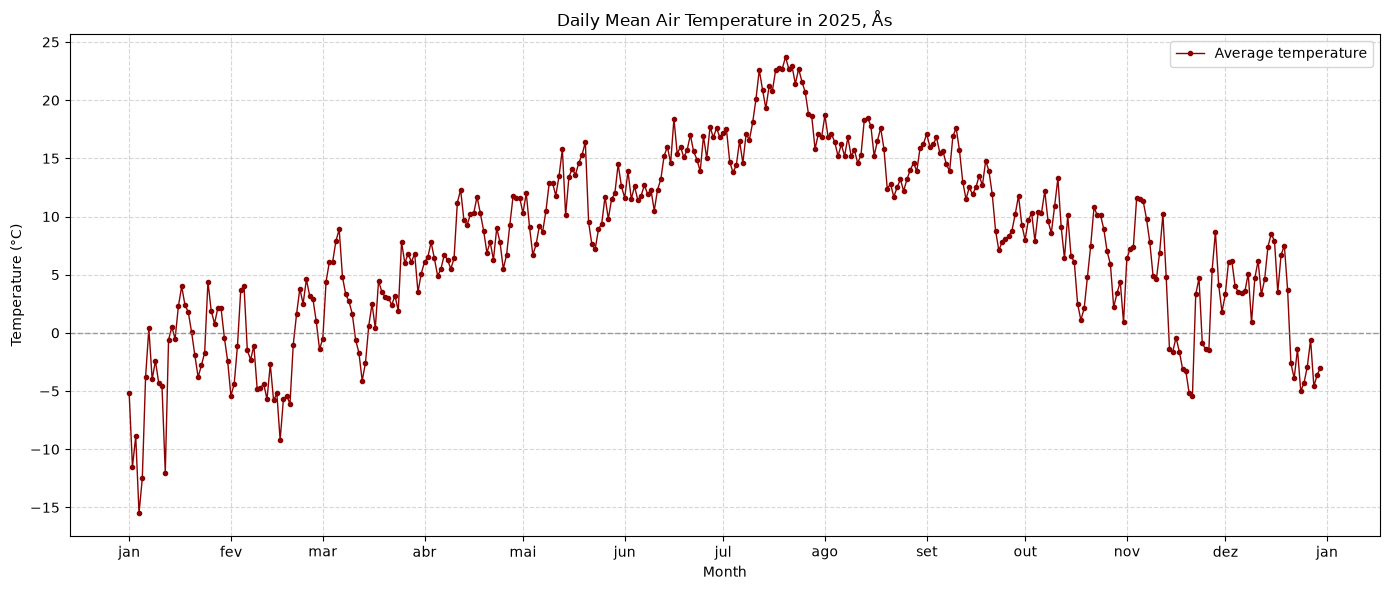

In [133]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["referenceTime"],
    df["value"],
    marker='o',
    linestyle='-',
    linewidth=1,
    markersize=3,
    color='darkred',
    label='Average temperature'
)

# Zero-degree reference
plt.axhline(
    0,
    color="gray",
    linestyle="--",
    linewidth=1,
    alpha=0.75
)

# Format dates
plt.gca().xaxis.set_major_locator(mdates.MonthLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%b"))

# Labels
plt.title('Daily Mean Air Temperature in 2025, Ås')
plt.xlabel('Month')
plt.ylabel('Temperature (°C)')

# Styling
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()

plt.show()

Print a summary table

In [134]:
summary = (
    df["value"]
    .agg(["mean", "median", "min", "max"])
    .reset_index()
)
summary_table = (
    "Summary of Daily Mean Air Temperature in Ås (2025)\n"
    + tabulate(
        summary,
        headers=["Statistic", "Temperature (°C)"],
        tablefmt="outline",
        showindex=False,
        floatfmt=".2f"
    )
)
print(summary_table)

Summary of Daily Mean Air Temperature in Ås (2025)
+-------------+--------------------+
| Statistic   |   Temperature (°C) |
+=============+====================+
| mean        |               7.90 |
| median      |               8.40 |
| min         |             -15.50 |
| max         |              23.70 |
+-------------+--------------------+


### Task 2

Request precipitation data

In [135]:
# Define endpoint and parameters
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
 'sources': 'SN17850',
 'elements': 'sum(precipitation_amount P1D)',
 'referencetime': '2025-01-01/2025-12-31',
}

# Issue an HTTP GET request
r = requests.get(endpoint, parameters, auth=(client_id, ''))
# Extract JSON data
json = r.json()

# Check if the request worked, print out any errors
if r.status_code == 200:
    data_precip = json['data']
    print('Data retrieved from frost.met.no!')
else:
    print('Error! Returned status code %s' % r.status_code)
    print('Message: %s' % json['error']['message'])
    print('Reason: %s' % json['error']['reason'])


Data retrieved from frost.met.no!


In [136]:
# This will return a Dataframe with all of the observations in a table format
# Intructions: https://frost.met.no/python_example.html

rows_precip = []

for i in range(len(data_precip)):
    row = pd.DataFrame(data_precip[i]['observations'])
    row['referenceTime'] = data_precip[i]['referenceTime']
    row['sourceId'] = data_precip[i]['sourceId']
    rows_precip.append(row)

df_precip = pd.concat(rows_precip, ignore_index=True)

df_precip['referenceTime'] = pd.to_datetime(df_precip['referenceTime'])

df_precip.head()

,elementId,value,unit,timeOffset,timeResolution,timeSeriesId,performanceCategory,exposureCategory,qualityCode,referenceTime,sourceId
0,sum(precipitation_amount P1D),5.4,mm,PT18H,P1D,0,C,2,NaN,2025-01-01 00:00:00+00:00,SN17850:0
1,sum(precipitation_amount P1D),6.6,mm,PT6H,P1D,0,C,2,0.0,2025-01-01 00:00:00+00:00,SN17850:0
2,sum(precipitation_amount P1D),0.0,mm,PT18H,P1D,0,C,2,NaN,2025-01-02 00:00:00+00:00,SN17850:0
3,sum(precipitation_amount P1D),1.9,mm,PT6H,P1D,0,C,2,0.0,2025-01-02 00:00:00+00:00,SN17850:0
4,sum(precipitation_amount P1D),0.1,mm,PT18H,P1D,0,C,2,NaN,2025-01-03 00:00:00+00:00,SN17850:0


In [137]:
# Create a df with the precipiation measuremente of the PT6H timeOffset

df_precip_6H = df_precip[df_precip['timeOffset'] == "PT6H"]
df_precip_6H.head()

,elementId,value,unit,timeOffset,timeResolution,timeSeriesId,performanceCategory,exposureCategory,qualityCode,referenceTime,sourceId
1,sum(precipitation_amount P1D),6.6,mm,PT6H,P1D,0,C,2,0.0,2025-01-01 00:00:00+00:00,SN17850:0
3,sum(precipitation_amount P1D),1.9,mm,PT6H,P1D,0,C,2,0.0,2025-01-02 00:00:00+00:00,SN17850:0
5,sum(precipitation_amount P1D),0.1,mm,PT6H,P1D,0,C,2,0.0,2025-01-03 00:00:00+00:00,SN17850:0
7,sum(precipitation_amount P1D),0.0,mm,PT6H,P1D,0,C,2,0.0,2025-01-04 00:00:00+00:00,SN17850:0
9,sum(precipitation_amount P1D),0.0,mm,PT6H,P1D,0,C,2,0.0,2025-01-05 00:00:00+00:00,SN17850:0


In [138]:
# Create a list with the total precipitation of each month for the PT6H timeOffset
monthly_total = []

for i in range(1,13):
    total = df_precip_6H[df_precip_6H['referenceTime'].dt.month==i]['value'].sum()
    monthly_total.append(total)

monthly_total

[np.float64(86.4),
 np.float64(38.800000000000004),
 np.float64(15.7),
 np.float64(21.6),
 np.float64(35.400000000000006),
 np.float64(93.3),
 np.float64(77.00000000000001),
 np.float64(110.30000000000001),
 np.float64(145.6),
 np.float64(124.89999999999999),
 np.float64(84.89999999999998),
 np.float64(116.3)]

In [139]:
# one date for each month (15)
months_dates = []

for i in range(1,13):
    date = "2025-"+str(i)+"-15"
    months_dates.append(date)

months_dates = pd.to_datetime(months_dates)


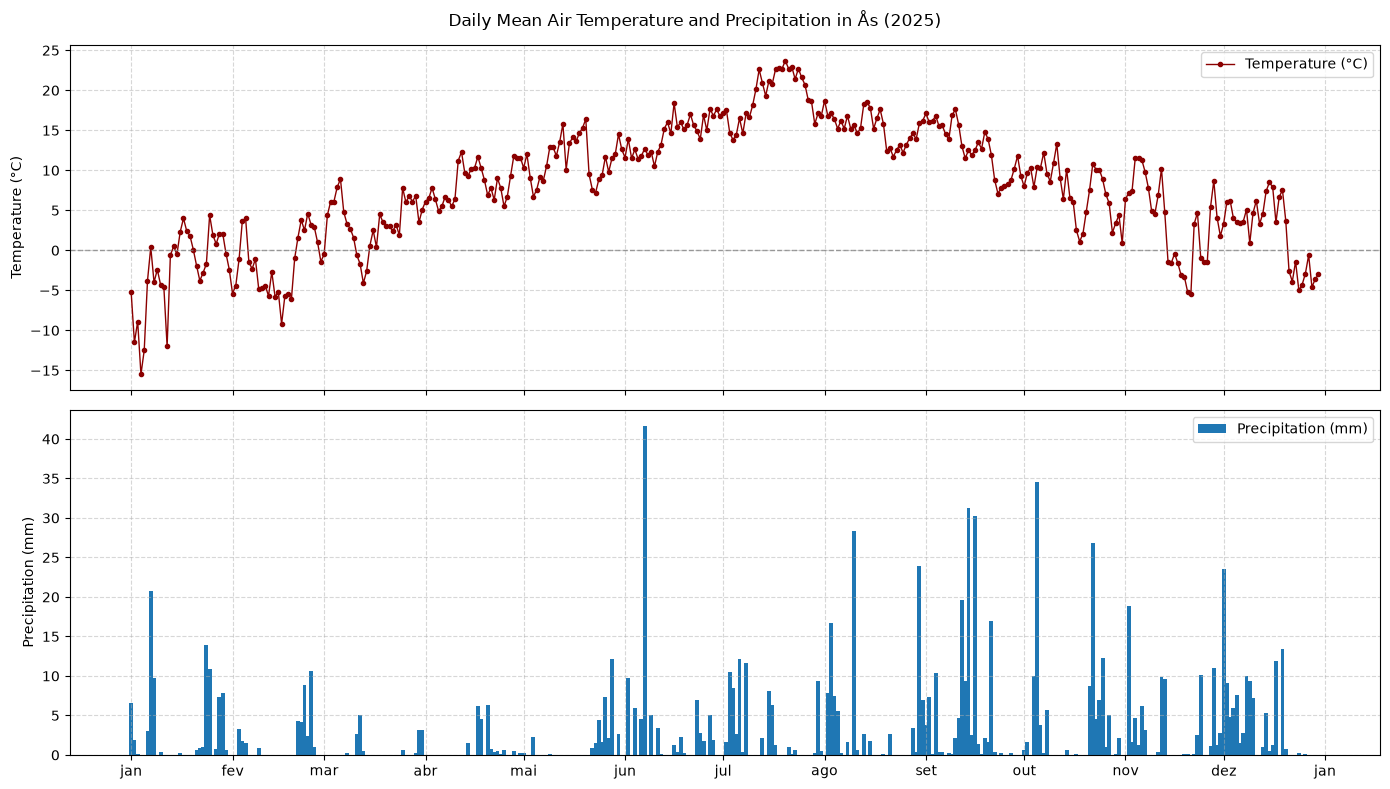

In [140]:
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(14, 8))

# Precipitation by day

ax1.plot(
    df['referenceTime'],
    df['value'],
    color='darkred',
    marker='o',
    linestyle='-',
    linewidth=1,
    markersize=3,
)
ax1.set_ylabel("Temperature (°C)")


ax2.bar(
    df_precip_6H['referenceTime'],
    df_precip_6H['value'],
    width=1.2,
)
ax2.set_ylabel("Precipitation (mm)")

# Zero-degree reference
ax1.axhline(
    0,
    color="gray",
    linestyle="--",
    linewidth=1,
    alpha=0.75
)

#Labels
fig.suptitle("Daily Mean Air Temperature and Precipitation in Ås (2025)")
ax1.xaxis.set_major_locator(mdates.MonthLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b"))

# Styling
ax1.grid(True, linestyle='--', alpha=0.5)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(["Precipitation (mm)"], loc="upper right")
ax1.legend(["Temperature (°C)"], loc="upper right")
fig.tight_layout()
plt.show()

### Task 3

In [141]:
# Define endpoint and parameters
endpoint = 'https://frost.met.no/observations/v0.jsonld'

# -- Year 1925 --
parameters_1925 = {
 'sources': 'SN17850',
 'elements': 'mean(air_temperature P1D)',
 'referencetime': '1925-01-01/1925-12-31',
}

r_1925 = requests.get(endpoint, parameters_1925, auth=(client_id,''))
json_1925 = r_1925.json()

# -- Year 2025 --
parameters_2025 = {
 'sources': 'SN17850',
 'elements': 'mean(air_temperature P1D)',
 'referencetime': '2025-01-01/2025-12-31',
}

r_2025 = requests.get(endpoint, parameters_2025, auth=(client_id,''))
json_2025 = r_2025.json()



In [142]:
# Check if the request worked, print out any errors

# -- Year 1925 --
if r_1925.status_code == 200:
    data_1925 = json_1925['data']
    print('1925: data retrieved from frost.met.no!')
else:
    print('1925: Error! Returned status code %s' % r_1925.status_code)
    print('Message: %s' % json_1925['error']['message'])
    print('Reason: %s' % json_1925['error']['reason'])

# -- Year 2025 --
if r_2025.status_code == 200:
    data_2025 = json_2025['data']
    print('2025: data retrieved from frost.met.no!')
else:
    print('2025: Error! Returned status code %s' % r_2025.status_code)
    print('Message: %s' % json_2025['error']['message'])
    print('Reason: %s' % json_2025['error']['reason'])



1925: data retrieved from frost.met.no!
2025: data retrieved from frost.met.no!


In [143]:
# This will return a Dataframe with all of the observations in a table format
# Intructions: https://frost.met.no/python_example.html

# --- DataFrame 1925 ---
rows_1925 = []

for i in range(len(data_1925)):
    row = pd.DataFrame(data_1925[i]['observations'])
    row['referenceTime'] = data_1925[i]['referenceTime']
    row['sourceId'] = data_1925[i]['sourceId']
    rows_1925.append(row)

df_1925 = pd.concat(rows_1925, ignore_index=True)

# --- DataFrame 2025 ---
rows_2025 = []

for i in range(len(data_2025)):
    row = pd.DataFrame(data_2025[i]['observations'])
    row['referenceTime'] = data_2025[i]['referenceTime']
    row['sourceId'] = data_2025[i]['sourceId']
    rows_2025.append(row)

df_2025 = pd.concat(rows_2025, ignore_index=True)


In [144]:
# Convert the time column from text to real datetime values
df_1925['referenceTime'] = pd.to_datetime(df_1925['referenceTime'])
df_2025['referenceTime'] = pd.to_datetime(df_2025['referenceTime'])

# Keep only one series for 2025 (timeOffset PT0H) to get one row per day
df_2025_0H = df_2025[df_2025['timeOffset'] == 'PT0H']


In [145]:
# Day of the year (1-365) lets both years share the same x-axis
df_1925['day'] = df_1925['referenceTime'].dt.dayofyear
df_2025_0H['day'] = df_2025_0H['referenceTime'].dt.dayofyear

In [146]:
df_temp_diff = pd.concat([df_1925.set_index('day')['value'], df_2025_0H.set_index('day')['value']], axis=1)
df_temp_diff.columns = ['1925', '2025']
df_temp_diff['diff'] = df_temp_diff['2025'] - df_temp_diff['1925']
df_temp_diff.head()

,1925,2025,diff
day,,,
1,1.3,-5.2,-6.5
2,4.1,-11.5,-15.6
3,2.1,-8.9,-11.0
4,0.1,-15.5,-15.6
5,-2.2,-12.5,-10.3


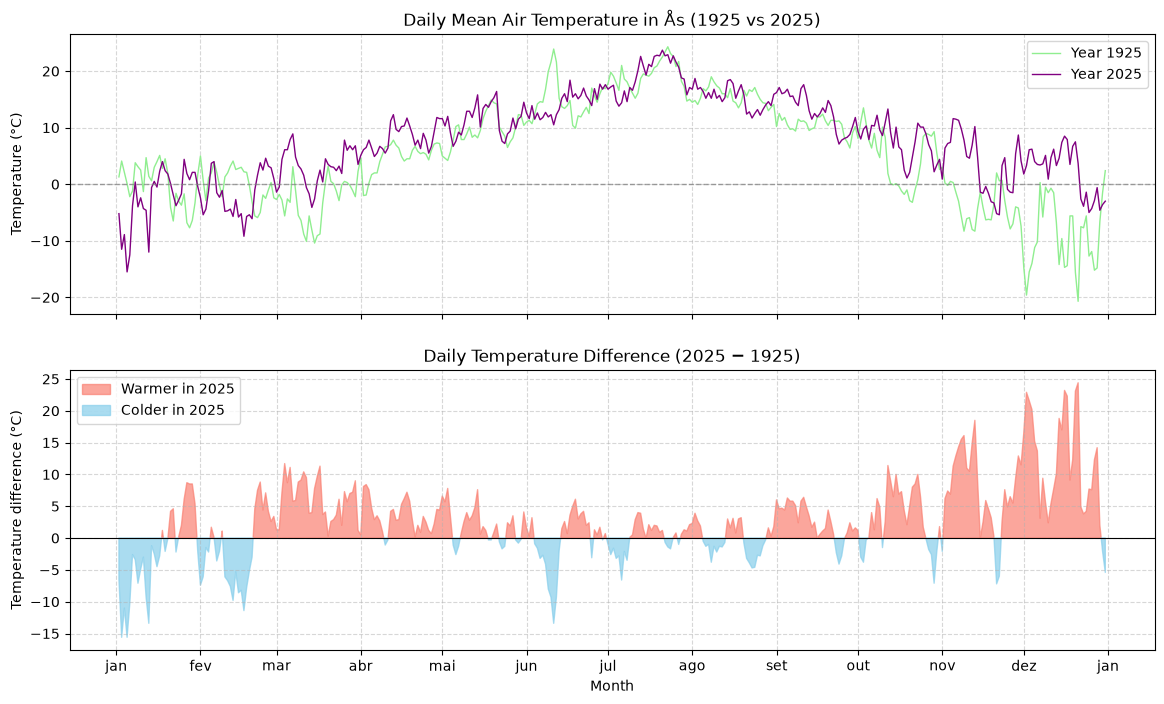

In [147]:
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(14, 8))


# Top: temperature in 1925 and 2025, blue = 1925, red = 2025
ax1.plot(
    df_1925["day"], 
    df_1925["value"],
    linestyle='-', 
    linewidth=1, 
    color='lightgreen', 
    label='Year 1925'
)

ax1.plot(
    df_2025_0H["day"], 
    df_2025_0H["value"],
    linestyle='-', 
    linewidth=1, 
    color='purple', 
    label='Year 2025'
)


# Bottom: difference (2025 - 1925), red = warmer in 2025, blue = colder
# Temperature difference: 2025 - 1925
diff = df_temp_diff['diff']

# Fill positive differences in red
ax2.fill_between(
    df_temp_diff.index, 
    diff, 
    0, 
    where=diff >= 0,
    color="salmon", 
    alpha=0.7, 
    interpolate=True
)

# Fill negative differences in blue
ax2.fill_between(
    df_temp_diff.index, 
    diff, 
    0, 
    where=diff < 0,
    color="skyblue", 
    alpha=0.7, 
    interpolate=True
)


# Top plot
ax1.set_title("Daily Mean Air Temperature in Ås (1925 vs 2025)")
ax1.xaxis.set_major_locator(mdates.MonthLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax1.axhline(0, color="gray", linestyle="--", linewidth=1, alpha=0.75)
ax1.set_ylabel("Temperature (°C)")
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc="upper right")


# Bottom plot
ax2.set_title("Daily Temperature Difference (2025 − 1925)")
ax2.axhline(0, color="black", linewidth=0.8)
ax2.set_ylabel("Temperature difference (°C)")
ax2.set_xlabel("Month")
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(["Warmer in 2025", "Colder in 2025"], loc="upper left")




In [148]:
# Creating a summary table of the air temperature data
summary_1925 = df_1925["value"].agg(["mean", "median","min", "max"])
summary_1925.index = ["Mean", "Median", "Minimum", "Maximum"]

summary_2025 = df_2025_0H["value"].agg(["mean", "median","min", "max"])
summary_2025.index = ["Mean", "Median", "Minimum", "Maximum"]

# Print the table: title and header
print("=" * 40)
print(f"|{'TEMPERATURE (°C)':^38}|")
print("=" * 40)
print(f"| {'YEAR':^10} | {'1925':^10} | {'2025':^10} |")
print("=" * 40)

# Print one row per statistic
print(f"| {'Mean':<10} | {summary_1925['Mean']:^10.2f} | {summary_2025['Mean']:^10.2f} |")
print("-" * 40)
print(f"| {'Median':<10} | {summary_1925['Median']:^10.2f} | {summary_2025['Median']:^10.2f} |")
print("-" * 40)
print(f"| {'Minimum':<10} | {summary_1925['Minimum']:^10.2f} | {summary_2025['Minimum']:^10.2f} |")
print("-" * 40)
print(f"| {'Maximum':<10} | {summary_1925['Maximum']:^10.2f} | {summary_2025['Maximum']:^10.2f} |")
print("=" * 40)

|           TEMPERATURE (°C)           |
|    YEAR    |    1925    |    2025    |
| Mean       |    5.31    |    7.90    |
----------------------------------------
| Median     |    5.30    |    8.40    |
----------------------------------------
| Minimum    |   -20.70   |   -15.50   |
----------------------------------------
| Maximum    |   24.30    |   23.70    |


### Task 4

In [149]:
def number_heat_waves(df: pd.DataFrame) -> list[tuple]:
    '''Finds periods within a pd.DataFrame where temperatures have been at or below
    27 degrees celsius for five or more consecutie days.

    Parameters
    ----------
    df : pd.DataFrame
        Table of data. Must containt 'elements': 'max(air_temperature P1D)'.

    Returns
    -------
    heat_waves : List[tuple]
        A list containing tuples where elements of the tuple are:
         - First element is the start_day of a heat wave.
         - Second element is the end_day of a heat wave.
         - Third element is the number of consecutive days of a heat wave period.

    '''
    consecutive_days = 0
    heat_waves = []

    for i in range(len(df)):
        if df['T >= 27'].iloc[i]:
            if consecutive_days == 0:
                start_day = df['day'].iloc[i]

            consecutive_days += 1
        else:
            if consecutive_days >= 5:
                end_day = df['day'].iloc[i - 1]
                heat_waves.append((start_day, end_day, consecutive_days))

            consecutive_days = 0

    if consecutive_days >= 5:
        end_day = df['day'].iloc[-1]
        heat_waves.append((start_day, end_day, consecutive_days))

    return heat_waves


In [150]:
def find_station_name(source: str) -> str:
    '''Find the name of a weather station from its ID via the Frost API.

    Parameters
    ----------
    source : str
        The unique identifier of the weather station (e.g., 'SN17850').

    Returns
    -------
    str
        The name of the station (e.g., 'Ås').
    '''
    # Fetching station name
    endpoint = 'https://frost.met.no/sources/v0.jsonld'
    parameters = {
        'ids': source
    }
    # Issue HTTP GET request to the 'sources' reference in order to fetch station_name
    response = requests.get(url=endpoint, params=parameters, auth=(client_id,''))
    station_name = response.json()['data'][0]['name']
    
    return station_name

In [151]:
def create_heatwave_summary(source, referencetime):
    '''Creates a summary for heatwave periods where max temperatures during a day
    have been over 27 degrees celsius over five or more consecutive days.
    
    Parameters
    ----------
    source : str
        Source of the observation, station ID.
    referencetime : str
        The reference time for the data request.
        Format: YYYY-MM-DD/YYYY-MM-DD.

    Returns
    -------
    heatwave_summary.yml : yml file
        Summary of heatwave periods in .yml format. 
    '''
    
    # Pull data from Frost API
    parameters = {
        'sources': source,
        'elements': 'max(air_temperature P1D)',
        'referencetime': referencetime,
    }
    df = data_request_df(**parameters)
    
    # Filtering dataframe to 
    df['day'] = df['referenceTime'].dt.date
    df_temp_per_day = df.groupby('day')['value'].max().reset_index()
    df_temp_per_day['T >= 27'] = df_temp_per_day['value'] >= 27
    
    # Finding period for heatwave
    start_date = number_heat_waves(df_temp_per_day)[0][0]    
    end_date = number_heat_waves(df_temp_per_day)[0][1]
    
    # Finding station name
    station_name = find_station_name(source)

    # yaml dictionary to save
    yml_dict = {
        'dates': [f'{start_date} - {end_date}'],
        'station_id': source,
        'station_name': station_name,
        'year': start_date.year
    }

    # Save to file
    with open('heatwave_summary.yml', 'w') as f:
        yaml.dump(yml_dict, f, sort_keys=False)
    

create_heatwave_summary('SN17850', '2025-01-01/2025-12-31')

Data retrieved from frost.met.no!


### Task 5

Define a function for moving average 

In [152]:
def rolling_mean(
        values: pd.Series,
        window: int = 7
) -> pd.Series:
    """
    Returns rolling average for the input Series.

    Args:
    values: pd.Series with numerical values.
    window: Size of rolling window. Default value is 7.

    Returns:
    pd.Series with average values in window.
    """

    return (
        values
        .rolling(
            window=window,
            center=True,
            min_periods=1
        ).mean()
    )

Apply to the 2025 mean temperature

In [153]:
df["rolling_mean"] = rolling_mean(df["value"])

Make a plot

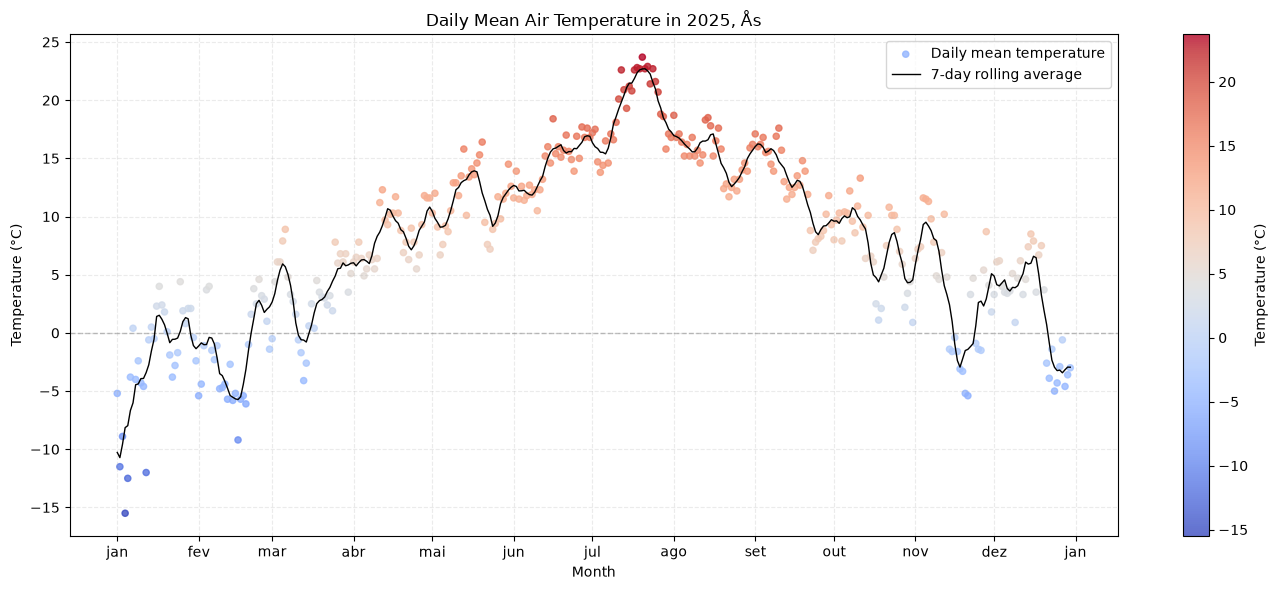

In [154]:
plt.figure(figsize=(14, 6))

# Color-coded daily temperatures
scatter = plt.scatter(
    x=df["referenceTime"],
    y=df["value"],
    c=df["value"],
    cmap="coolwarm",
    s=20,
    alpha=0.8,
    label="Daily mean temperature"
)

# Smoothed temperature curve
plt.plot(
    df["referenceTime"],
    df["rolling_mean"],
    color="black",
    linewidth=1,
    label="7-day rolling average",
    zorder=3
)

# Colorbar
plt.colorbar(scatter, label="Temperature (°C)")

# Zero-degree reference
plt.axhline(
    0,
    color="gray",
    linestyle="--",
    linewidth=1,
    alpha=0.5
)

# Format dates
plt.gca().xaxis.set_major_locator(mdates.MonthLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%b"))

# Labels
plt.title('Daily Mean Air Temperature in 2025, Ås')
plt.xlabel('Month')
plt.ylabel('Temperature (°C)')

# Styling
plt.grid(True, linestyle='--', alpha=0.25)
plt.legend()
plt.tight_layout()

plt.show()